In [16]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()

# Import data (Make sure to parse dates. Consider setting index column to 'date'.)
df = pd.read_csv('fcc-forum-pageviews.csv',index_col ='date')

# Clean data
df = df[(df['value']<= df['value'].quantile(0.975))&(df['value']> df['value'].quantile(0.025))]


def draw_line_plot():
    # Draw line plot
    fig = plt.figure(figsize = (10,6))
    df['value'].plot()
    plt.title('Daily freeCodeCamp Forum Page Views 5/2016-12/2019')
    plt.xlabel('date')
    plt.ylabel('value')

    # Save image and return fig (don't change this part)
    fig.savefig('line_plot.png')
    return fig

def draw_bar_plot():
    # Copy and modify data for monthly bar plot
    df.index = pd.to_datetime(df.index)
    df_bar = df.groupby([pd.Grouper(freq = 'M')]).mean()
    df_bar['year'] = df_bar.index.year
    df_bar['month'] = df_bar.index.month
    pivot_table = df_bar.pivot_table(values = 'value', index = 'year',columns = 'month')
    

    # Draw bar plot
    fig, ax = plt.subplots(figsize=(10, 6))
    pivot_table.plot(kind = 'bar',ax = ax)
    plt.title('Average views per month for 5/2016-12/2019')
    plt.xlabel('year')
    plt.ylabel('value ')
    plt.legend(title='Months', labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])



    # Save image and return fig (don't change this part)
    fig.savefig('bar_plot.png')
    return fig

def draw_box_plot():
    # Prepare data for box plots (this part is done!)
    df_box = df.copy()
    df_box.reset_index(inplace=True)
    df_box['year'] = [d.year for d in df_box.date]
    df_box['month'] = [d.strftime('%b') for d in df_box.date]

    # Draw box plots (using Seaborn)
   
    month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
    fig, axes = plt.subplots(1,2,figsize = (15,8))
    sns.boxplot(x = 'year',y = 'value', data = df_box, ax = axes[0])
    axes[0].set_title('year wise Box  plot (Trend)')
    axes[0].set_xlabel('year')
    axes[0].set_ylabel('value')
    
    
    sns.boxplot(x = 'month',y = 'value',order = month_order, data = df_box, ax = axes[1])
    axes[1].set_title('month wise Box  plot (seasonality)')
    axes[1].set_xlabel('month')
    axes[1].set_ylabel('value')
    
    plt.tight_layout()



    # Save image and return fig (don't change this part)
    fig.savefig('box_plot.png')
    return fig


In [17]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()

# Import data (Make sure to parse dates. Consider setting index column to 'date'.)
df = pd.read_csv('fcc-forum-pageviews.csv',index_col ='date')

# Clean data
df = df[(df['value']<= df['value'].quantile(0.975))&(df['value']> df['value'].quantile(0.025))]


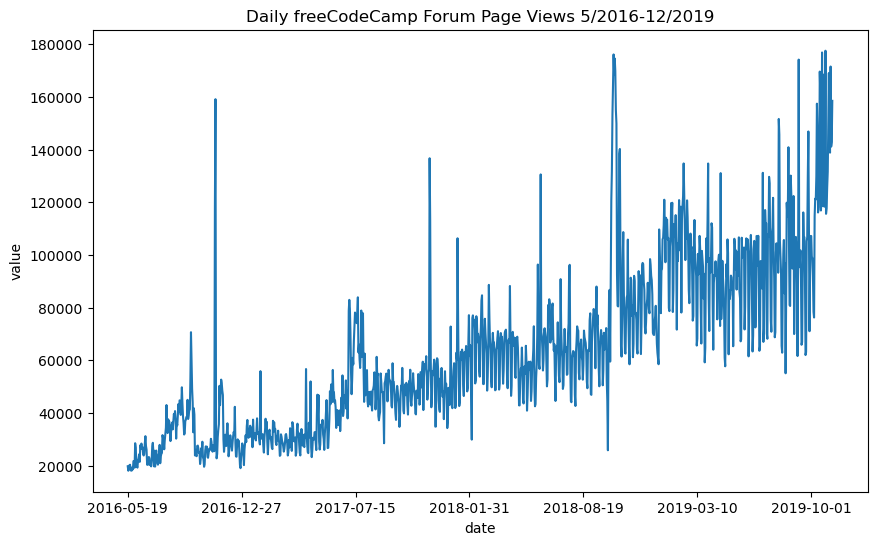

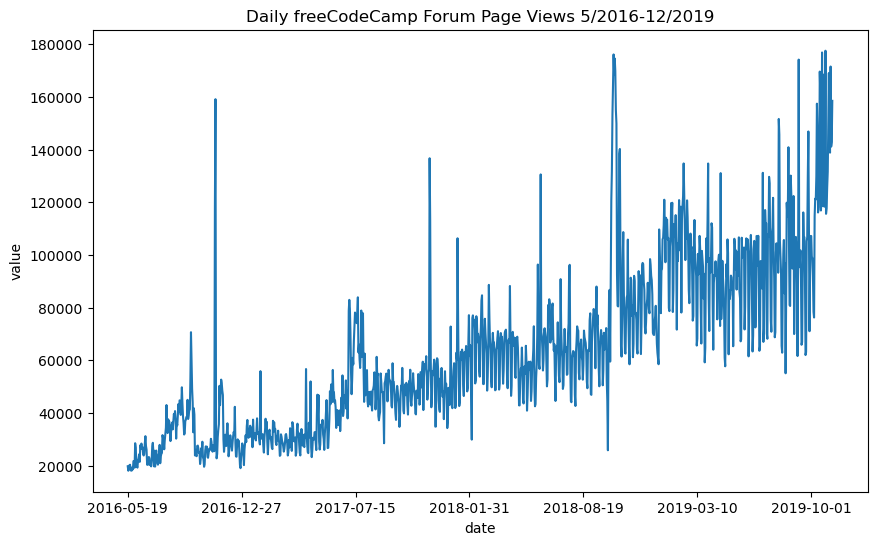

In [18]:
draw_line_plot()

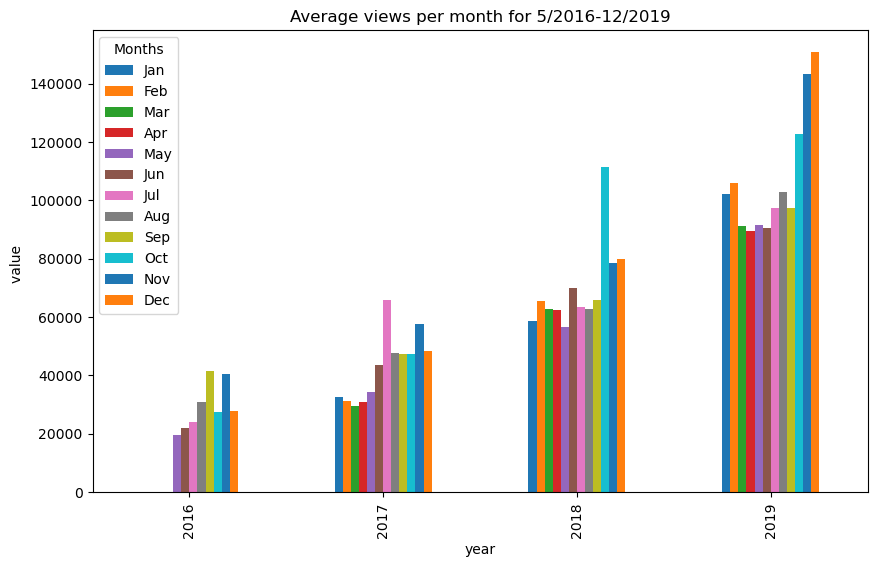

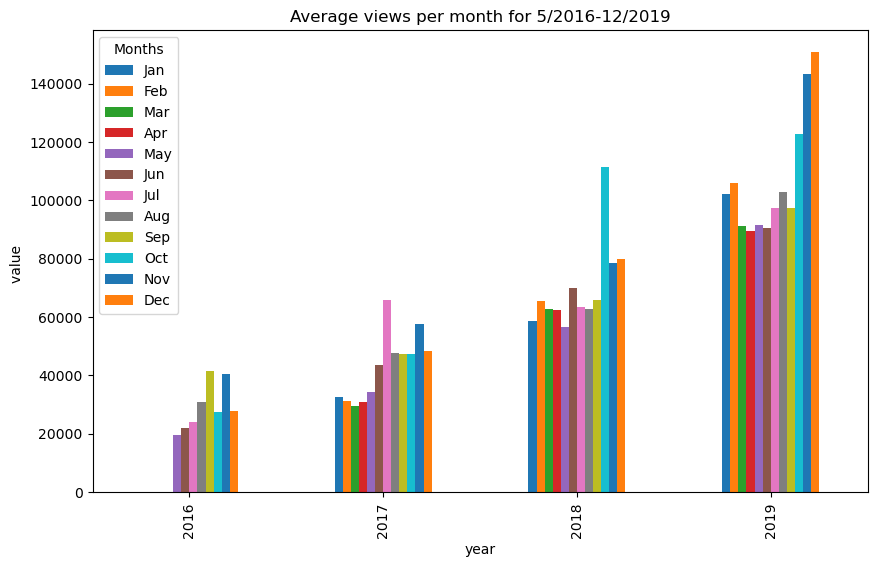

In [19]:
draw_bar_plot()

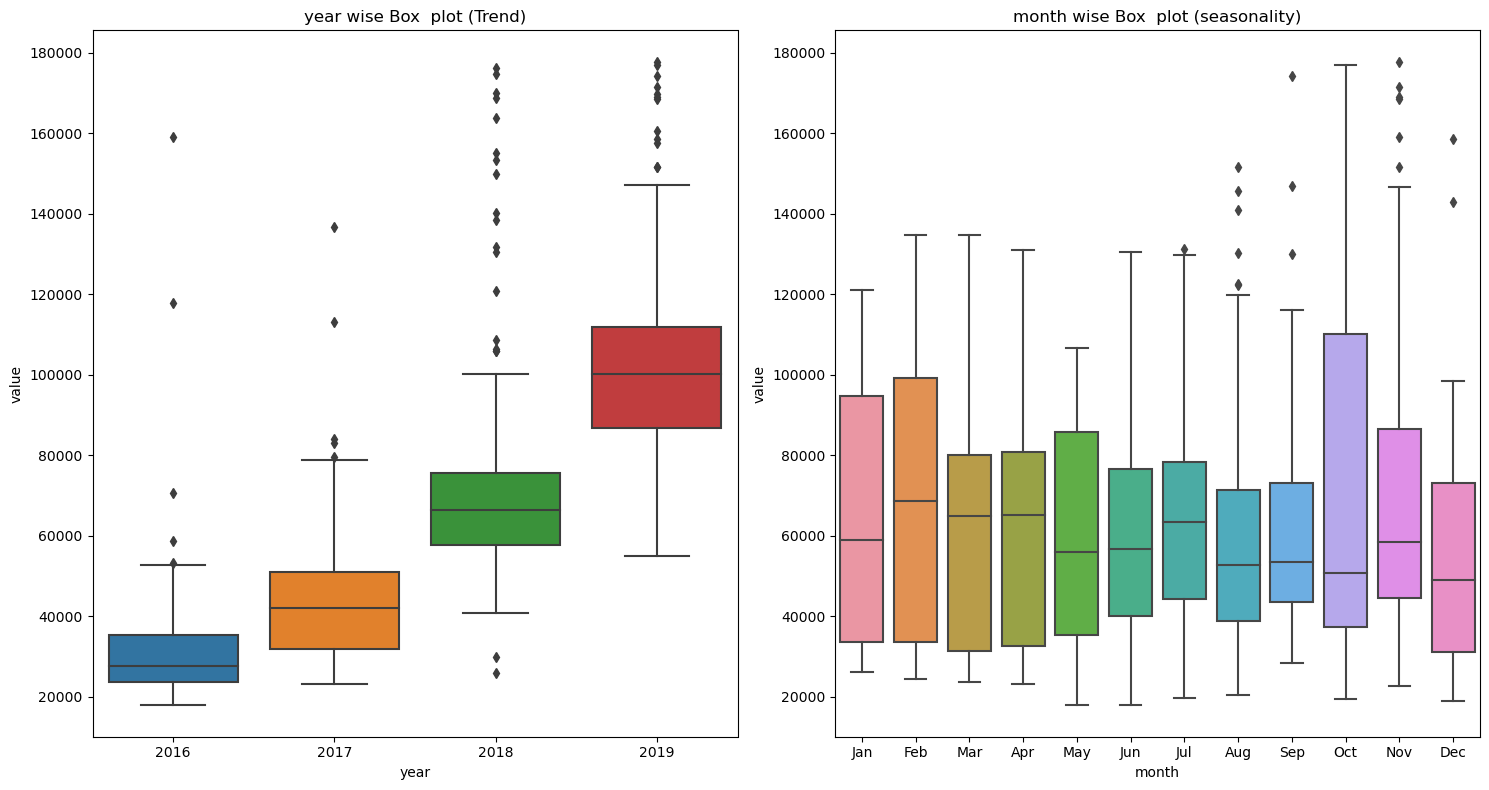

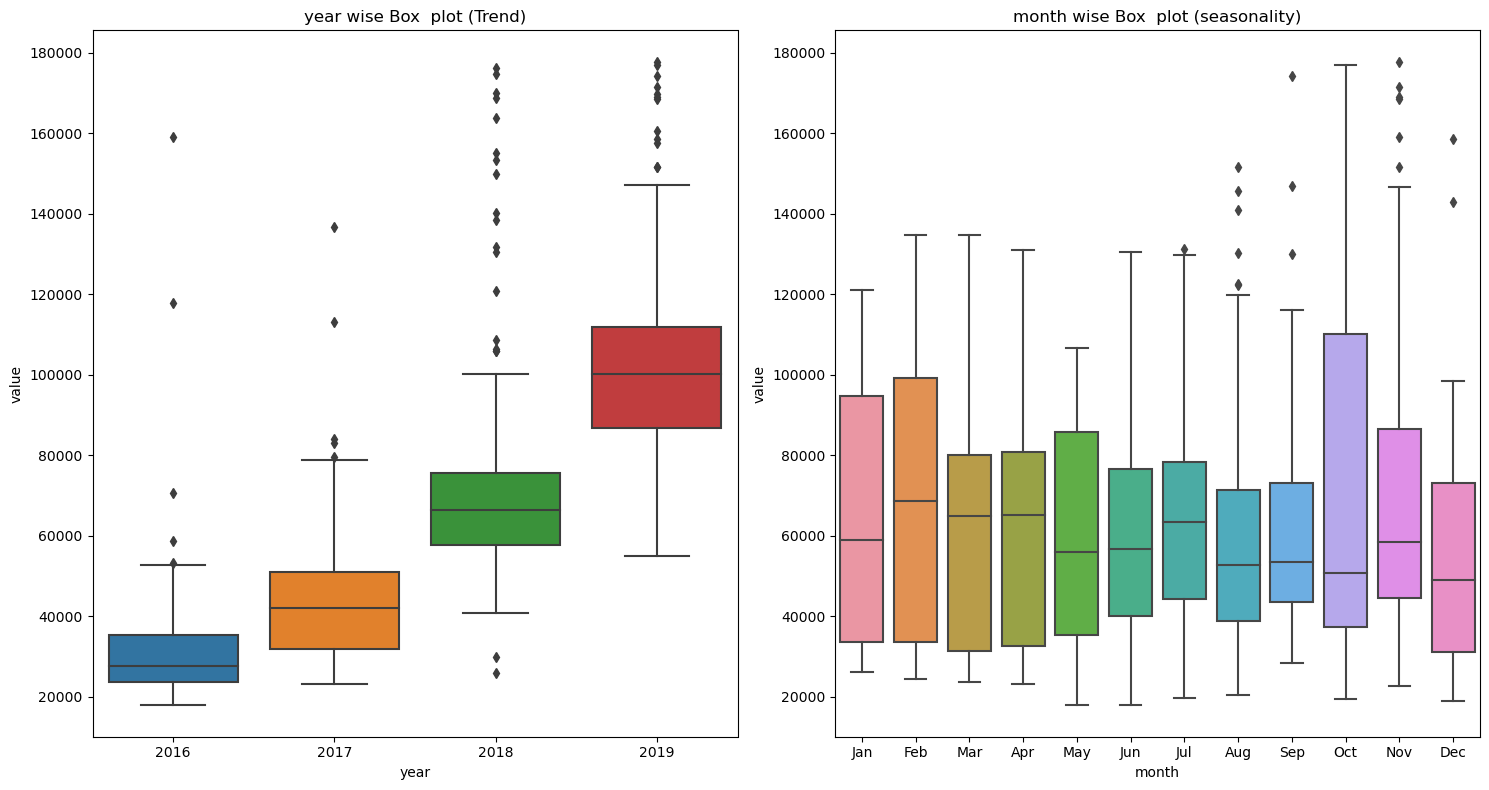

In [20]:
draw_box_plot()